<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/12-supervised-learning/04_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: What Drives House Values?

In 1997, two statisticians, Kelley Pace and Ronald Barry, assembled a dataset from the 1990 US Census: every **block group** in California (a neighbourhood of typically 600 to 3,000 people), with its location, the age of its housing, its rooms, residents and households, its median income, and its **median house value**. It has since become one of the most used datasets in machine learning teaching, and it's a good test of linear models: the patterns are real but not simple.

The goal: predict a block group's median house value from the other census figures, as accurately and honestly as possible, using **linear models only**, and understand what drives the predictions. Along the way:

1. **Audit** the data, and find two places where it isn't what it seems
2. **Split** it, holding out a test set
3. Climb a **ladder of models**, one idea at a time, with cross-validation deciding each step
4. Watch a model with many features **collapse**, and fix it with regularisation
5. Find out what "new data" means for **geographic** data, and how it changes the answer
6. **Diagnose** the final model with a learning curve
7. **Test** once, and map where the model is wrong
8. **Read** the model: what it says about income and house values
9. See how far a non-linear model gets, as a preview of Module 14

## Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/12-supervised-learning/data/california_housing.csv"
local = Path("data/california_housing.csv")
housing = pd.read_csv(local if local.exists() else DATA_URL)
print(housing.shape)
housing.head()

(20640, 9)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.23,37.88,41,880,129,322,126,8.3252,452600
1,-122.22,37.86,21,7099,1106,2401,1138,8.3014,358500
2,-122.24,37.85,52,1467,190,496,177,7.2574,352100
3,-122.25,37.85,52,1274,235,558,219,5.6431,341300
4,-122.25,37.85,52,1627,280,565,259,3.8462,342200


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## Step 1: Audit the data

Each row is a block group. The columns:

| column | meaning |
|---|---|
| `longitude`, `latitude` | the block group's location |
| `housing_median_age` | median age of the houses, in years |
| `total_rooms`, `total_bedrooms` | rooms and bedrooms, **summed over the whole block group** |
| `population`, `households` | people and households in the block group |
| `median_income` | median household income, in tens of thousands of 1990 dollars |
| `median_house_value` | the target: median value of owner-occupied homes, in dollars |

In [3]:
housing.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.6,2.0,-124.4,-121.8,-118.5,-118.0,-114.3
latitude,20640.0,35.6,2.1,32.5,33.9,34.3,37.7,42.0
housing_median_age,20640.0,28.6,12.6,1.0,18.0,29.0,37.0,52.0
total_rooms,20640.0,2635.8,2181.6,2.0,1447.8,2127.0,3148.0,39320.0
total_bedrooms,20640.0,537.9,421.2,1.0,295.0,435.0,647.0,6445.0
population,20640.0,1425.5,1132.5,3.0,787.0,1166.0,1725.0,35682.0
households,20640.0,499.5,382.3,1.0,280.0,409.0,605.0,6082.0
median_income,20640.0,3.9,1.9,0.5,2.6,3.5,4.7,15.0
median_house_value,20640.0,206855.8,115395.6,14999.0,119600.0,179700.0,264725.0,500001.0


Two things in that summary deserve a closer look. The maximum house value is exactly **500,001**, and the maximum housing age is exactly **52**. Suspiciously round. Histograms show what's going on:

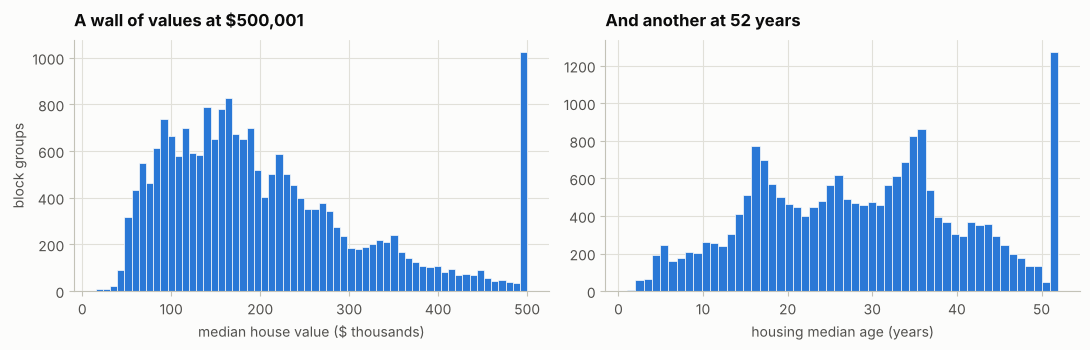

value at the cap: 965 block groups (4.7%)
age at the cap:   1273 block groups (6.2%)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(housing["median_house_value"] / 1000, bins=60, color=PALETTE[0], edgecolor=SURFACE, linewidth=0.5)
axes[0].set_xlabel("median house value ($ thousands)")
axes[0].set_ylabel("block groups")
axes[0].set_title("A wall of values at $500,001")
axes[1].hist(housing["housing_median_age"], bins=52, color=PALETTE[0], edgecolor=SURFACE, linewidth=0.5)
axes[1].set_xlabel("housing median age (years)")
axes[1].set_title("And another at 52 years")
fig.tight_layout()
plt.show()

capped_value = housing["median_house_value"] >= 500_001
capped_age = housing["housing_median_age"] >= 52
print(f"value at the cap: {capped_value.sum()} block groups ({capped_value.mean():.1%})")
print(f"age at the cap:   {capped_age.sum()} block groups ({capped_age.mean():.1%})")

Both columns were **capped** (the technical word is **censored**) when the data was published: any block group with a median value above $500,000 is recorded as $500,001, and any housing age above 52 as 52. A spike at the maximum value is the classic sign.

They need different treatment:

- **The capped values are targets.** For those 965 block groups, we don't know the true value, only that it's above $500,000. Training on them would teach the model that the most expensive areas are worth exactly $500,001; evaluating on them would penalise a model for correctly predicting $800,000. So this project **removes them** and states the consequence plainly: **the model is only for block groups worth under $500,000.** It can't say anything reliable about the most expensive areas.
- **The capped ages are features.** "52" really means "52 or older", which is still informative, so those rows stay. The model will treat 52 as just a number, which is a small distortion worth knowing about.

The second surprise is in the totals. Rooms, bedrooms, people and households are counts for the whole block group, so big block groups have big numbers regardless of what the houses are like. Ratios describe the houses themselves:

In [5]:
data = housing[~capped_value].reset_index(drop=True)
data["rooms_per_household"] = data["total_rooms"] / data["households"]
data["bedrooms_per_room"] = data["total_bedrooms"] / data["total_rooms"]
data["people_per_household"] = data["population"] / data["households"]

print(f"kept {len(data):,} block groups")
data[["rooms_per_household", "bedrooms_per_room", "people_per_household"]].describe().round(2)

kept 19,675 block groups


,rooms_per_household,bedrooms_per_room,people_per_household
count,19675.00,19675.00,19675.00
mean,5.36,0.22,3.10
std,2.29,0.06,10.63
min,0.85,0.10,0.69
25%,4.41,0.18,2.45
50%,5.18,0.20,2.84
75%,5.97,0.24,3.30
max,132.53,1.00,1243.33


Mostly sensible (about 5 rooms and 3 people per household), with some wild maximums: block groups with over 100 rooms per household, or hundreds of people per household. These are real records, probably holiday-home areas and institutions such as dormitories or prisons, and they're the kind of extreme values that can throw a linear model off. Logarithms (section 4 of the lesson) will tame them.

## Step 2: Split

Hold out 20% of the block groups as a test set, untouched until Step 7. Everything before that uses 5-fold cross-validation on the training 80%.

In [6]:
from sklearn.model_selection import KFold, train_test_split

y_all = data["median_house_value"]
X_all = data.drop(columns="median_house_value")
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=0)
print(f"training: {len(X_train):,}   test: {len(X_test):,}")

training: 15,740   test: 3,935


## Step 3: A ladder of models

Start simple and add one idea at a time, keeping each change only if cross-validation says it helps. RMSE, in dollars, is the measure.

In [7]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures, SplineTransformer, StandardScaler

RAW = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms",
       "population", "households", "median_income"]
RATIOS = ["longitude", "latitude", "housing_median_age", "median_income", "households",
          "rooms_per_household", "bedrooms_per_room", "people_per_household"]
SKEWED = ["median_income", "households", "rooms_per_household", "people_per_household"]
OTHER = ["housing_median_age", "bedrooms_per_room"]
LOCATION = ["longitude", "latitude"]


def cv_rmse(model, X=X_train, y=y_train, splitter=cv, groups=None):
    with warnings.catch_warnings(), np.errstate(over="ignore", invalid="ignore"):
        warnings.simplefilter("ignore")
        scores = cross_val_score(model, X, y, cv=splitter, groups=groups, scoring="neg_root_mean_squared_error")
    return -scores


def log_target(regressor):
    """Fit on log(value), predict back in dollars."""
    return TransformedTargetRegressor(regressor, func=np.log, inverse_func=np.exp)


def features(location_step):
    """Logs of the skewed features, standardised; the rest standardised; location handled by location_step."""
    return ColumnTransformer([
        ("logs", make_pipeline(FunctionTransformer(np.log, feature_names_out="one-to-one"), StandardScaler()), SKEWED),
        ("other", StandardScaler(), OTHER),
        ("location", location_step, LOCATION),
    ])


ladder = {}
baseline = np.sqrt(np.mean((y_train - y_train.mean()) ** 2))
ladder["1. predict the mean"] = np.array([baseline])
ladder["2. linear, raw columns"] = cv_rmse(make_pipeline(StandardScaler(), LinearRegression()), X_train[RAW])
ladder["3. linear, ratios instead of totals"] = cv_rmse(make_pipeline(StandardScaler(), LinearRegression()), X_train[RATIOS])
ladder["4. + logs of skewed features and target"] = cv_rmse(log_target(make_pipeline(features(StandardScaler()), LinearRegression())))
ladder["5. + smooth curves for latitude, longitude"] = cv_rmse(log_target(make_pipeline(features(SplineTransformer(n_knots=10)), LinearRegression())))

for name, scores in ladder.items():
    print(f"{name:<46} RMSE ${scores.mean():>8,.0f}")

1. predict the mean                            RMSE $  97,163
2. linear, raw columns                         RMSE $  61,493
3. linear, ratios instead of totals            RMSE $  62,741
4. + logs of skewed features and target        RMSE $  59,487
5. + smooth curves for latitude, longitude     RMSE $  56,549


What each rung says:

- **Rung 2**: a plain linear model on the raw columns cuts the error from about $97,000 (always predicting the average) to about $61,500.
- **Rung 3**: replacing totals with per-household ratios makes it slightly **worse**. That's surprising, and worth understanding rather than ignoring: the ratios have extreme outliers (over 100 rooms per household), and a linear model gives those few points enormous influence.
- **Rung 4**: taking logarithms of the skewed features, and of the target, pulls in those extremes and fixes the problem. Modelling log value also means errors are treated as **proportional**: being $20,000 off on a $100,000 house is a bigger mistake than on a $400,000 one, which matches how people think about prices.
- **Rung 5**: house values depend heavily on location, but not in a straight line: prices don't rise steadily from east to west. Splines let the model learn a curve along latitude and another along longitude. A clear gain.

But a curve for latitude **plus** a curve for longitude still can't describe a coastline. Being near the coast matters, and the California coast runs diagonally. That needs the **combination** of latitude and longitude: an interaction.

## Step 4: Many features, and a collapse

Products of the latitude splines with the longitude splines (a **tensor-product spline**) let the model learn a smooth surface over the map. That's a lot of features:

In [8]:
surface = make_pipeline(SplineTransformer(n_knots=8), PolynomialFeatures(2, interaction_only=True, include_bias=False))
n_location = surface.fit_transform(X_train[LOCATION]).shape[1]
print(f"location features: {n_location}, plus {len(SKEWED) + len(OTHER)} others")

ols_scores = cv_rmse(log_target(make_pipeline(features(surface), LinearRegression())))
print("RMSE per fold, ordinary least squares:", [f"${s:,.0f}" for s in ols_scores])
print(f"mean: ${ols_scores.mean():,.0f}")

location features: 210, plus 6 others


RMSE per fold, ordinary least squares: ['$1,957,196', '$52,769', '$60,686', '$53,306', '$54,433']
mean: $435,678


Disaster. Most folds are reasonable, some better than rung 5, but in at least one fold the error is in the millions or worse. (The exact numbers change between library versions, because the fit is so unstable that tiny differences in rounding send it somewhere else: that instability is itself the symptom.) A few block groups sit in parts of the map where the training folds had almost no data, and with 210 location features and no restraint, the fitted surface shoots off to absurd values there. In log space that's a large error; turned back into dollars with `exp`, it becomes an astronomical one.

This is **variance** in its purest form (lesson section 5): the model fits each training set so closely that its predictions in sparse regions depend wildly on exactly which points it saw. Ridge regression is the fix:

In [9]:
alphas = [0.01, 0.1, 0.3, 1, 3, 10, 30, 100]
ridge_random = {a: cv_rmse(log_target(make_pipeline(features(surface), Ridge(alpha=a)))).mean() for a in alphas}
for a, s in ridge_random.items():
    print(f"alpha {a:>6}: RMSE ${s:,.0f}")

alpha   0.01: RMSE $54,455
alpha    0.1: RMSE $54,662
alpha    0.3: RMSE $54,838
alpha      1: RMSE $55,058
alpha      3: RMSE $55,265
alpha     10: RMSE $55,678
alpha     30: RMSE $56,531
alpha    100: RMSE $58,511


Even a tiny penalty brings every fold back to sensible predictions, and the surface model becomes the best so far. The penalty stops weights from growing huge to fit a handful of points, which is exactly what produced the wild predictions. (Note that the spline features aren't standardised: they're already on a 0 to 1 scale, and standardising columns that are almost always zero would blow up the rare non-zero values.)

With these random folds, the smallest penalty scores best. But that's not the whole story.

## Step 5: What does "new data" mean for a map?

Block groups next to each other are similar: same weather, same schools, same commute. In a random split, almost every test block group has neighbours in the training data, so the model can "look up" the local price level. That's fine if the model will be used **where we already have data**, such as filling in missing values within California. It's optimistic if the model will be used for **a region it has never seen**.

To measure the second situation, split by **location** instead: cut the map into cells of half a degree (about 50 km) and keep whole cells together with `GroupKFold`, so the validation block groups are always in regions the model hasn't seen.

In [10]:
from sklearn.model_selection import GroupKFold

cells = (np.floor(X_train["latitude"] / 0.5).astype(int) * 1000 + np.floor(X_train["longitude"] / 0.5).astype(int)).to_numpy()
print(f"{len(np.unique(cells))} map cells")
spatial = GroupKFold(n_splits=5)
ridge_spatial = {a: cv_rmse(log_target(make_pipeline(features(surface), Ridge(alpha=a))), splitter=spatial, groups=cells).mean()
                 for a in alphas}
rung5_spatial = cv_rmse(log_target(make_pipeline(features(SplineTransformer(n_knots=10)), LinearRegression())),
                        splitter=spatial, groups=cells).mean()

171 map cells


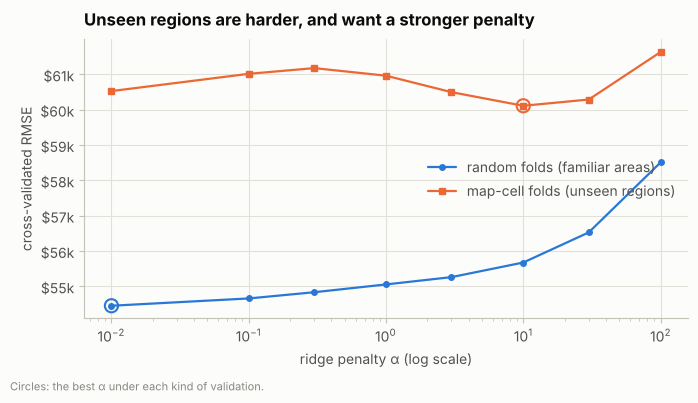

random folds:   best α = 0.01, RMSE $54,455
map-cell folds: best α = 10, RMSE $60,115
(rung 5, additive curves, on map-cell folds: $60,926)


In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alphas, list(ridge_random.values()), color=PALETTE[0], marker="o", markersize=4, label="random folds (familiar areas)")
ax.plot(alphas, list(ridge_spatial.values()), color=PALETTE[1], marker="s", markersize=4, label="map-cell folds (unseen regions)")
for scores, colour in [(ridge_random, PALETTE[0]), (ridge_spatial, PALETTE[1])]:
    best = min(scores, key=scores.get)
    ax.scatter([best], [scores[best]], s=90, facecolors="none", edgecolors=colour, linewidths=1.5, zorder=4)
ax.set_xscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v / 1000:.0f}k"))
ax.set_xlabel("ridge penalty α (log scale)")
ax.set_ylabel("cross-validated RMSE")
ax.set_title("Unseen regions are harder, and want a stronger penalty")
ax.legend(loc="center right")
fig.text(0.01, 0.01, "Circles: the best α under each kind of validation.", color=MUTED, fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()
best_random = min(ridge_random, key=ridge_random.get)
best_spatial = min(ridge_spatial, key=ridge_spatial.get)
print(f"random folds:   best α = {best_random}, RMSE ${ridge_random[best_random]:,.0f}")
print(f"map-cell folds: best α = {best_spatial}, RMSE ${ridge_spatial[best_spatial]:,.0f}")
print(f"(rung 5, additive curves, on map-cell folds: ${rung5_spatial:,.0f})")

Two findings that a single random split would never have shown:

- **Unseen regions are much harder.** The error jumps by about $5,000 to $6,000. Part of every random-fold score was the model recognising familiar neighbourhoods. On unseen regions, the map surface barely beats the simpler additive curves of rung 5 (by under $1,000): its extra detail is mostly local knowledge that doesn't transfer.
- **The best penalty depends on the question.** For familiar areas, a light penalty lets the surface follow local detail. For unseen regions, local detail doesn't transfer, so a stronger penalty, which keeps the surface smoother, does better.

Neither number is "the" accuracy. They answer different questions, and an honest report gives the one that matches how the model will be used. This project's model is meant for block groups within California, among areas like those it was trained on, so it uses **random folds** to choose α, and the test set from the same random split for the final number. The map-cell result is the warning label: in a new region, expect errors around $60,000, not $55,000.

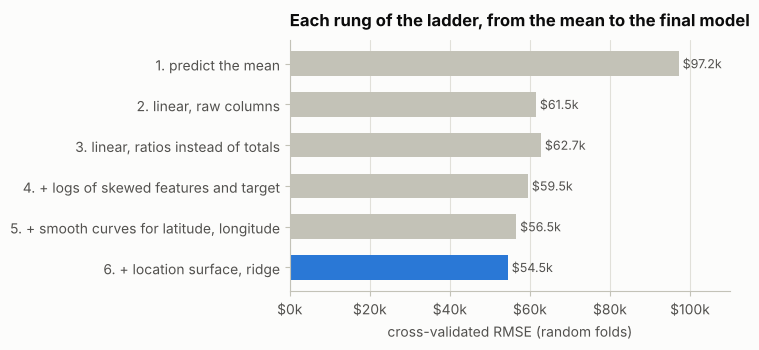

In [12]:
final = log_target(make_pipeline(features(surface), Ridge(alpha=best_random)))
ladder["6. + location surface, ridge"] = np.array([ridge_random[best_random]])

order = list(ladder)[::-1]
values = [ladder[k].mean() for k in order]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(order, values, color=[PALETTE[0] if k.startswith("6") else AXIS for k in order], height=0.6)
for i, v in enumerate(values):
    ax.text(v + 1000, i, f"${v / 1000:.1f}k", va="center", color=INK_2, fontsize=9)
ax.set_xlim(0, 110_000)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v / 1000:.0f}k"))
ax.grid(axis="y", visible=False)
ax.set_xlabel("cross-validated RMSE (random folds)")
ax.set_title("Each rung of the ladder, from the mean to the final model")
fig.tight_layout()
plt.show()

From $97,000 to about $54,500. The biggest single step was the first linear model; after that, the gains came from **features** (logs, then location) and from **regularisation**, which made a rich set of location features usable at all. The collapsed least squares model isn't on the chart: its average error was in the millions.

## Step 6: Diagnose with a learning curve

Is the final model limited by **data** (variance) or by its **form** (bias)? A learning curve answers that:

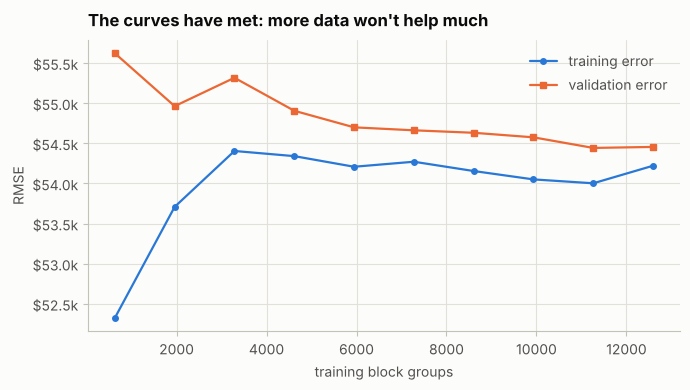

with 12,592 examples: training $54,221, validation $54,455


In [13]:
from sklearn.model_selection import learning_curve

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sizes, train_scores, val_scores = learning_curve(
        final, X_train, y_train, train_sizes=np.linspace(0.05, 1.0, 10), cv=cv,
        scoring="neg_root_mean_squared_error")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sizes, -train_scores.mean(axis=1), color=PALETTE[0], marker="o", markersize=4, label="training error")
ax.plot(sizes, -val_scores.mean(axis=1), color=PALETTE[1], marker="s", markersize=4, label="validation error")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v / 1000:.1f}k"))
ax.set_xlabel("training block groups")
ax.set_ylabel("RMSE")
ax.set_title("The curves have met: more data won't help much")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()
print(f"with {sizes[-1]:,} examples: training ${-train_scores.mean(axis=1)[-1]:,.0f}, validation ${-val_scores.mean(axis=1)[-1]:,.0f}")

The textbook **high-bias** shape (lesson section 7): with a few thousand examples, training and validation error have almost met, and both have flattened out. Doubling the data would barely help. The model is limited by what it **can express**: a sum of effects, each smooth, with location as the only interaction. Real house prices involve more interactions than that (the value of an extra room depends on income, location and age together). Getting further would need either many more hand-made interaction features, or a model family that finds interactions by itself, which is what Step 9 tries.

## Step 7: Test once, and map the errors

The model, the features and α are all fixed. Now the test set:

In [14]:
with np.errstate(over="ignore"):
    final.fit(X_train, y_train)
    pred_test = final.predict(X_test)
errors = y_test.to_numpy() - pred_test

rmse = np.sqrt(np.mean(errors ** 2))
mae = np.mean(np.abs(errors))
r2 = 1 - np.sum(errors ** 2) / np.sum((y_test - y_test.mean()) ** 2)
rng = np.random.default_rng(0)
boot = [np.sqrt(np.mean(errors[rng.integers(0, len(errors), len(errors))] ** 2)) for _ in range(2000)]
low, high = np.percentile(boot, [2.5, 97.5])

print(f"test RMSE ${rmse:,.0f}  (95% interval ${low:,.0f} to ${high:,.0f})")
print(f"test MAE  ${mae:,.0f}")
print(f"test R²   {r2:.3f}")
print(f"baseline RMSE on the test set: ${np.sqrt(np.mean((y_test - y_train.mean()) ** 2)):,.0f}")

test RMSE $55,755  (95% interval $53,553 to $58,106)
test MAE  $38,147
test R²   0.688
baseline RMSE on the test set: $99,865


The test RMSE lands close to the cross-validation estimate, so the evaluation was honest. The typical miss (MAE) is under $40,000, and the model explains about 70% of the variation in values below the cap.

Where does it go wrong? First, errors against predictions:

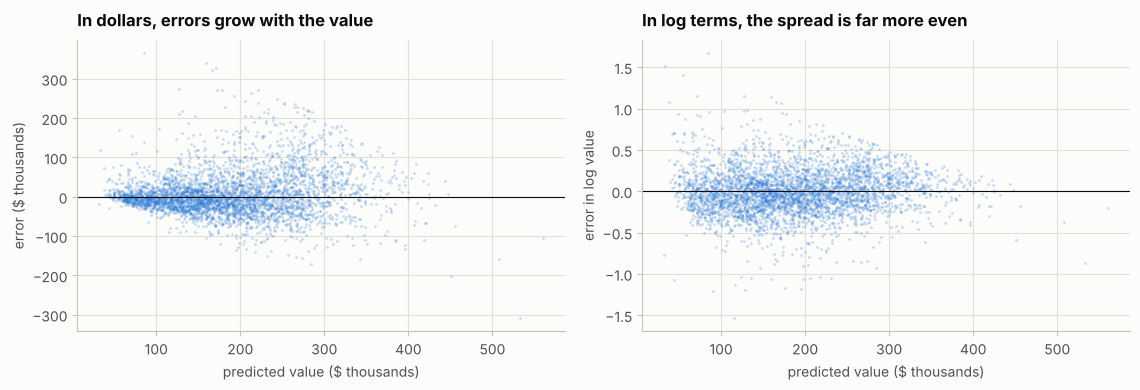

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
axes[0].scatter(pred_test / 1000, errors / 1000, s=4, color=PALETTE[0], alpha=0.25)
axes[0].axhline(0, color=INK, linewidth=0.8)
axes[0].set_xlabel("predicted value ($ thousands)")
axes[0].set_ylabel("error ($ thousands)")
axes[0].set_title("In dollars, errors grow with the value")
log_errors = np.log(y_test.to_numpy()) - np.log(pred_test)
axes[1].scatter(pred_test / 1000, log_errors, s=4, color=PALETTE[0], alpha=0.25)
axes[1].axhline(0, color=INK, linewidth=0.8)
axes[1].set_xlabel("predicted value ($ thousands)")
axes[1].set_ylabel("error in log value")
axes[1].set_title("In log terms, the spread is far more even")
fig.tight_layout()
plt.show()

The left panel is the **heteroscedasticity** from the lesson: dollar errors fan out as values rise, because a 15% miss is $15,000 on a cheap block group and $60,000 on an expensive one. On the log scale (right), the spread is much more even. That's why modelling log value was the right choice: the model's errors are roughly proportional, so its accuracy is better described in percent (half of the predictions are within about 16% of the true value) than as a single dollar figure.

Now on the map. Each dot is a test block group, coloured by how far off the prediction was, in percent:

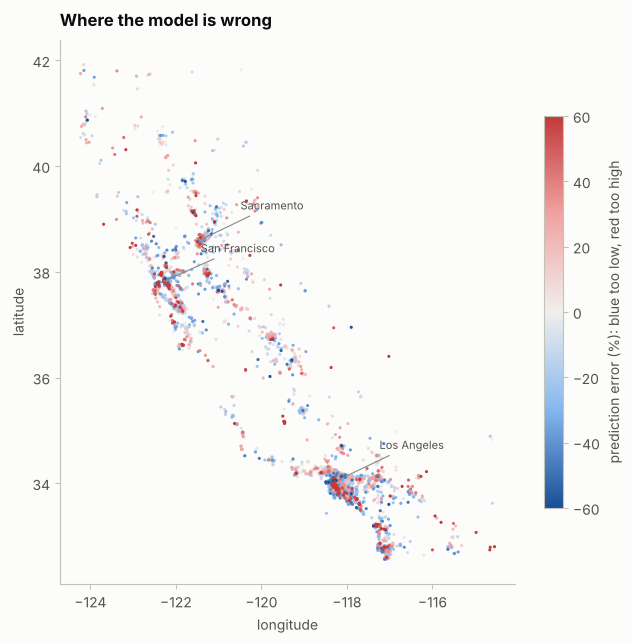

                         median_error_pct  typical_abs_error_pct  block_groups
region                                                                        
Bay Area                             -1.5                   15.4           722
Los Angeles area                      1.2                   15.4          1375
inland and south-east                 3.8                   15.9          1113
other coastal and north               0.6                   16.6           725


In [16]:
percent_error = 100 * (pred_test - y_test.to_numpy()) / y_test.to_numpy()
order_idx = np.argsort(np.abs(percent_error))           # draw the biggest errors on top
fig, ax = plt.subplots(figsize=(6.5, 6.5))
points = ax.scatter(X_test["longitude"].to_numpy()[order_idx], X_test["latitude"].to_numpy()[order_idx],
                    c=np.clip(percent_error[order_idx], -60, 60), cmap=DIVERGING, vmin=-60, vmax=60, s=5)
cbar = fig.colorbar(points, ax=ax, shrink=0.7)
cbar.set_label("prediction error (%): blue too low, red too high")
ax.set_aspect(1 / np.cos(np.radians(36)))          # keep the map's proportions roughly right
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.grid(False)
ax.set_title("Where the model is wrong")
for name, (lon, lat) in {"San Francisco": (-122.42, 37.77), "Los Angeles": (-118.24, 34.05), "Sacramento": (-121.49, 38.58)}.items():
    ax.annotate(name, xy=(lon, lat), xytext=(lon + 1.0, lat + 0.6), fontsize=8, color=INK_2,
                arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.8})
fig.tight_layout()
plt.show()

regions = pd.DataFrame({"lat": X_test["latitude"].to_numpy(), "lon": X_test["longitude"].to_numpy(), "pct": percent_error})
regions["region"] = np.select(
    [(regions.lat > 37.2) & (regions.lat < 38.3) & (regions.lon < -121.5),
     (regions.lat > 33.6) & (regions.lat < 34.4) & (regions.lon > -118.8) & (regions.lon < -117.6),
     regions.lon > -120.5],
    ["Bay Area", "Los Angeles area", "inland and south-east"], default="other coastal and north")
print(regions.groupby("region")["pct"].agg(median_error_pct="median", typical_abs_error_pct=lambda s: s.abs().median(), block_groups="size").round(1))

Two things stand out:

- **The size of the errors is about the same everywhere**: in every region, half the predictions are within about 15% to 17%. There's no part of the state where the model falls apart.
- **There are small regional biases.** Inland and south-eastern block groups are predicted about 4% too high on average, and the Bay Area about 1.5% too low. Small, but systematic: a user in the Bay Area should expect the model to undervalue slightly.

The map also shows that big errors aren't clustered in one place. They're scattered, often with a red dot next to a blue one. That's local variation a smooth surface can't capture: the difference between neighbouring streets, or between a waterfront and the blocks behind it. Capturing it would need finer location information than the census gives.

## Step 8: Read the model

The non-location features are standardised logs (or standardised values), and the target is log value, so their weights have a clean reading: roughly, **the percentage change in value for a one standard deviation change in the feature**, with everything else, including location, held fixed.

In [17]:
names = final.regressor_[0].get_feature_names_out()
weights = pd.Series(final.regressor_[-1].coef_, index=names)
main = weights[~weights.index.str.startswith("location")]
readable = main.rename(lambda n: n.split("__")[1]).sort_values()
print((100 * (np.exp(readable) - 1)).round(1).astype(str) + " % per 1 sd")

people_per_household    -8.8 % per 1 sd
housing_median_age      -1.2 % per 1 sd
households               0.8 % per 1 sd
bedrooms_per_room        5.3 % per 1 sd
rooms_per_household      6.4 % per 1 sd
median_income           28.7 % per 1 sd
dtype: str


**Median income** dominates: a block group one standard deviation richer (in log terms), at the same location and with the same housing, has a median value about 29% higher. **Crowding** pushes the other way: more people per household goes with lower values. The remaining effects are small, and some look odd taken alone (a higher share of bedrooms among rooms appearing to **raise** values, for example), because the features are correlated with each other and with location, so their weights share credit, as lesson section 2 warned. Income's effect is large and stable enough to trust; the small ones aren't worth over-interpreting.

The standard deviation of log income here is about 0.44, so "one standard deviation" means **income about 55% higher**. Put differently: with location fixed, house values rise less than proportionally with income, about 29% for 55% more income. That's a sensible, interpretable finding, and the kind of thing linear models are good at producing.

## Step 9: How far can a linear model go?

The learning curve said the linear model is limited by its form, not its data. To see how much that costs, compare a model that finds interactions by itself: **histogram gradient boosting**, a tree-based method you'll build from scratch in Module 14. It gets the same features (ratios, no logs needed), no tuning:

In [18]:
from sklearn.ensemble import HistGradientBoostingRegressor

boosting = HistGradientBoostingRegressor(random_state=0)
boost_cv = cv_rmse(boosting, X_train[RATIOS]).mean()
boost_spatial = cv_rmse(boosting, X_train[RATIOS], splitter=spatial, groups=cells).mean()
boosting.fit(X_train[RATIOS], y_train)
boost_test = np.sqrt(np.mean((y_test - boosting.predict(X_test[RATIOS])) ** 2))

comparison = pd.DataFrame({
    "random-fold CV": [ridge_random[best_random], boost_cv],
    "map-cell CV": [ridge_spatial[best_random], boost_spatial],
    "test": [rmse, boost_test],
}, index=["linear (ridge, location surface)", "gradient boosting, untuned"])
(comparison / 1000).round(1).astype(str).radd("$").add("k")

,random-fold CV,map-cell CV,test
"linear (ridge, location surface)",$54.5k,$60.5k,$55.8k
"gradient boosting, untuned",$42.9k,$53.9k,$43.6k


Gradient boosting is clearly ahead, around $43,600 against $55,800 on the test set. Trees combine features in ways the linear model can't, for example "high income **and** near the coast **and** newer houses". Its lead **shrinks** on unseen regions (from about $11,600 to roughly $7,000), because it too relies on recognising familiar places, but it's still ahead there.

That doesn't make the linear model useless. It's fast, it extrapolates more gently, and its income effect can be stated in one sentence. In many real projects, a well-built linear model is the baseline that a complex model has to justify beating, and sometimes it's the one that ships because people can understand it. Module 14 opens up the trees.

## Summary

| step | finding |
|---|---|
| audit | house values capped at $500,001 and ages at 52; capped targets removed, so the model only covers block groups under $500,000 |
| ratios | per-household ratios alone made a linear model **worse**, because of extreme outliers |
| logs | logs of skewed features and of the target fixed that, and made errors proportional |
| location | smooth curves for latitude and longitude helped; a surface over the map helped more |
| regularisation | the 210-feature surface **collapsed** under least squares (errors in the millions) and became the best model with ridge |
| validation | unseen regions cost about $5,000 to $6,000 more RMSE and prefer a stronger penalty |
| learning curve | high bias: more data won't help, a more expressive model would |
| test | RMSE about $56,000, MAE about $38,000, R² about 0.69; similar accuracy in every region, with small regional biases |
| comparison | untuned gradient boosting reaches about $44,000, with a smaller but real edge on unseen regions |

**Ideas to extend it:**

- Add the distance from each block group to the nearest big city (San Francisco, Los Angeles, San Diego, Sacramento) as a feature. Does it beat the spline surface, or add to it?
- Use `LassoCV` on the full feature set. Which location features survive, and how many?
- Build a model **with** the capped rows, and look at how its predictions behave near $500,000. What goes wrong, and why?
- Fit the model on map-cell folds with the stronger penalty, and compare its test errors region by region with the light-penalty model.